# 1. Análise e Previsão de Risco de Crédito

### 1.1. Introdução

A concessão de crédito é uma atividade que envolve riscos financeiros, especialmente quando existe a possibilidade de inadimplência por parte dos clientes.

Nesse contexto, a análise de dados e o Machine Learning podem auxiliar na identificação de padrões associados ao comportamento dos consumidores, contribuindo para uma avaliação mais criteriosa do risco de crédito.

Este projeto tem como objetivo analisar uma base de dados de clientes, identificar características relacionadas à inadimplência e desenvolver modelos de Machine Learning capazes de prever a probabilidade de um cliente não cumprir suas obrigações financeiras.

### 1.2. Objetivos

- Explorar e compreender as características dos clientes presentes na base de dados.
- Identificar possíveis padrões associados à inadimplência.
- Analisar a relação entre variáveis como renda, idade e valor do empréstimo.
- Desenvolver e comparar diferentes modelos de Machine Learning.
- Identificar o modelo com melhor desempenho e interpretar os resultados obtidos.

### 1.3. Problema de negócio

**É possível identificar clientes com maior risco de inadimplência utilizando informações como renda, idade e valor do empréstimo?**

A partir dessa questão, buscamos compreender quais características estão mais associadas à inadimplência e avaliar a capacidade dos modelos preditivos de identificar clientes potencialmente inadimplentes.

## 2. Importação das bibliotecas e carregamento dos dados

Nesta etapa, serão importadas as bibliotecas utilizadas para manipulação, análise e visualização dos dados, além das ferramentas necessárias para o desenvolvimento dos modelos preditivos.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

### 2.1. Carregamento dos dados

A base de dados utilizada contém informações de clientes, incluindo renda, idade, valor do empréstimo e histórico de inadimplência.

Essas informações serão utilizadas para investigar possíveis relações entre o perfil dos clientes e a ocorrência de inadimplência.

In [2]:
df = pd.read_csv('credit_data.csv')

In [3]:
df.shape

(2000, 5)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   clientid  2000 non-null   int64  
 1   income    2000 non-null   float64
 2   age       1997 non-null   float64
 3   loan      2000 non-null   float64
 4   default   2000 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 78.3 KB


In [5]:
df.head()

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1


## 3. Exploração inicial dos dados

Antes de iniciar as análises, é importante compreender as características da base de dados e verificar sua qualidade.

Nesta etapa, serão avaliadas as informações disponíveis, as estatísticas descritivas, a existência de valores ausentes ou duplicados e a distribuição dos registros de inadimplência.

### 3.1. Visualização dos Dados

Estatística descritiva

In [6]:
df.describe()

,clientid,income,age,loan,default
count,2000.000000,2000.000000,1997.000000,2000.000000,2000.000000
mean,1000.500000,45331.600018,40.807559,4444.369695,0.141500
std,577.494589,14326.327119,13.624469,3045.410024,0.348624
min,1.000000,20014.489470,-52.423280,1.377630,0.000000
25%,500.750000,32796.459717,28.990415,1939.708847,0.000000
50%,1000.500000,45789.117313,41.317159,3974.719419,0.000000
75%,1500.250000,57791.281668,52.587040,6432.410625,0.000000
max,2000.000000,69995.685578,63.971796,13766.051239,1.000000


Qualidade dos Dados

In [7]:
print(f"Quantidade de Registros Duplicados: {df.duplicated().sum()}")
print(f"Valores Ausentes por Variável: \n{df.isnull().sum()}")

Quantidade de Registros Duplicados: 0
Valores Ausentes por Variável: 
clientid    0
income      0
age         3
loan        0
default     0
dtype: int64


Distribuição de Inadimplência


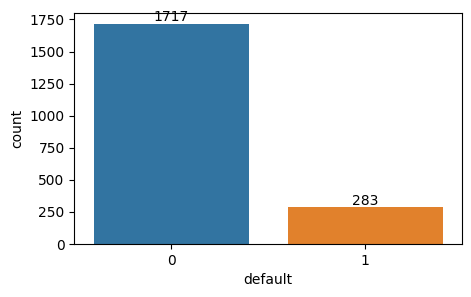

In [8]:
plt.figure(figsize = (5, 3))
ax = sns.countplot(x = df["default"], hue = df["default"], legend = False)
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.show()

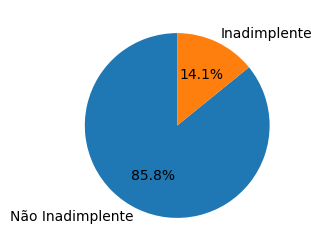

In [9]:
df_inadimplencia = df["default"].map({1:'Inadimplente', 0:'Não Inadimplente'})
counts = df_inadimplencia.value_counts()
plt.figure(figsize = (5, 3))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.show()

Distribuição dos Dados

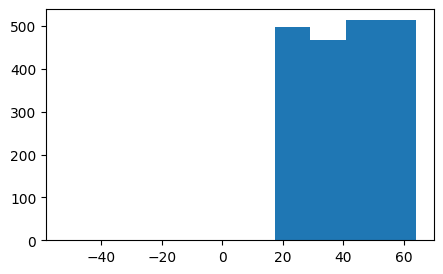

In [10]:
plt.figure(figsize = (5, 3))
plt.hist(x = df["age"]);

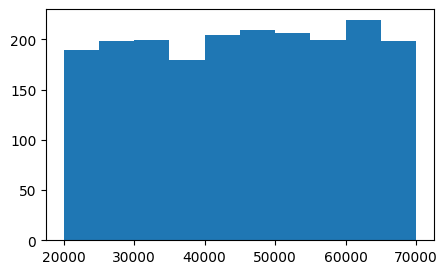

In [11]:
plt.figure(figsize = (5, 3))
plt.hist(x = df["income"]);

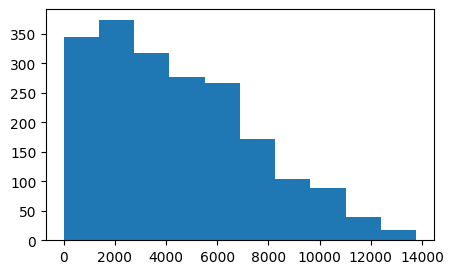

In [12]:
plt.figure(figsize = (5, 3))
plt.hist(x = df["loan"]);

## 4. Limpeza e preparação dos dados

Após a exploração inicial, vamos tratar possíveis inconsistências encontradas na base, garantindo que os dados estejam adequados para as análises e para o desenvolvimento dos modelos preditivos.

Substituindo Valores de Idade Negativos por Valores Nulos

In [13]:
df.loc[df['age'] < 0, 'age'] = np.nan

Conferindo Valores Nulos Após Tratamento

In [14]:
df.isnull().sum()

,0
clientid,0
income,0
age,6
loan,0
default,0


## 5. Análise exploratória dos dados

Nesta etapa, vamos investigar a relação entre as características dos clientes e a ocorrência de inadimplência. O objetivo é identificar padrões que possam ajudar a compreender quais fatores estão mais associados ao risco de crédito.

Comparação das variáveis por situação de inadimplência

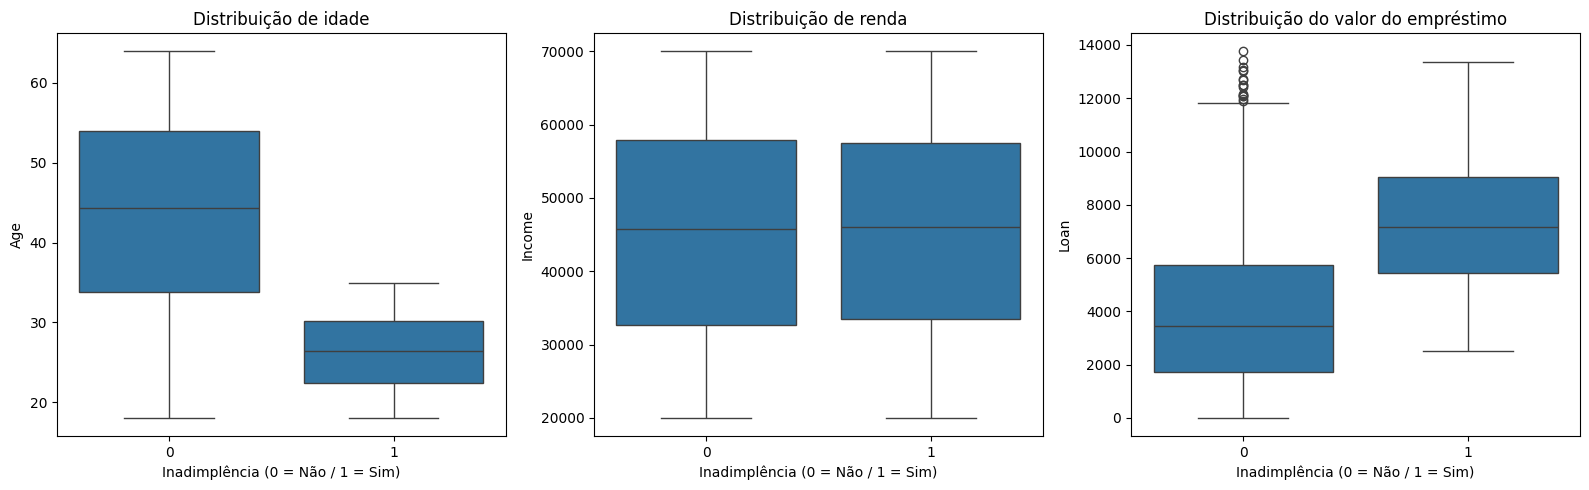

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variaveis = ['age', 'income', 'loan']
titulos = ['Distribuição de idade', 'Distribuição de renda', 'Distribuição do valor do empréstimo']

for ax, variavel, titulo in zip(axes, variaveis, titulos):
    sns.boxplot(data=df, x='default', y=variavel, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel('Inadimplência (0 = Não / 1 = Sim)')
    ax.set_ylabel(variavel.capitalize())

plt.tight_layout()
plt.show()

Taxa de inadimplência por faixa etária e valor do empréstimo

In [16]:
# Criando faixas etárias
df['faixa_etaria'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 45, 55, 100],
    labels=['Até 25', '26 a 35', '36 a 45', '46 a 55', 'Acima de 55']
)

# Criando grupos de valor de empréstimo
df['faixa_emprestimo'] = pd.qcut(
    df['loan'],
    q=4,
    labels=['Baixo', 'Médio-baixo', 'Médio-alto', 'Alto']
)

# Calculando a taxa de inadimplência por grupo
taxa_idade = df.groupby('faixa_etaria', observed=True)['default'].mean() * 100
taxa_emprestimo = df.groupby('faixa_emprestimo', observed=True)['default'].mean() * 100

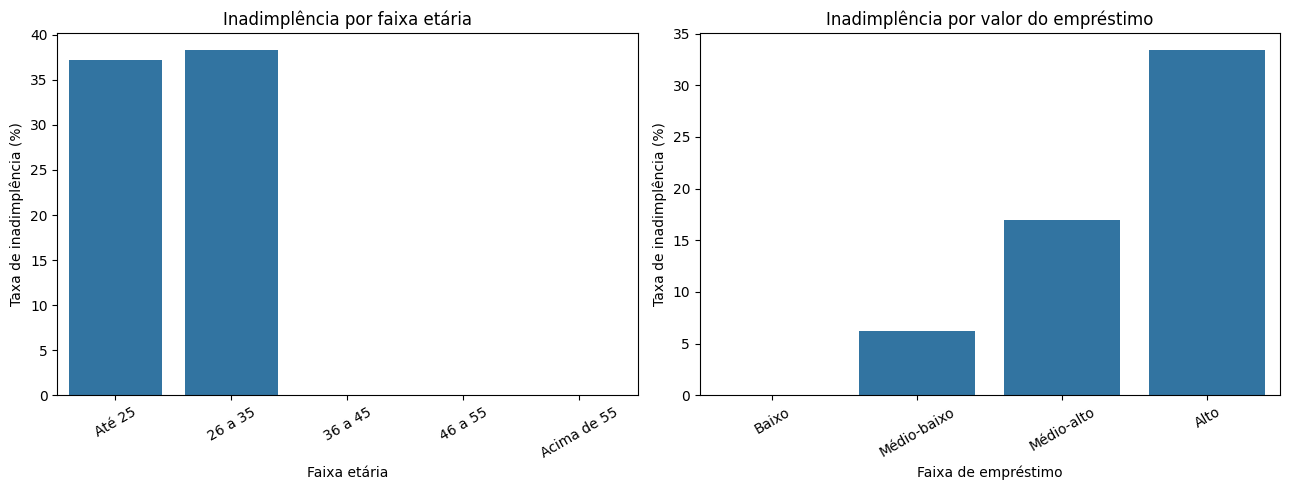

In [17]:
# Visualizando os resultados
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x=taxa_idade.index, y=taxa_idade.values, ax=axes[0])
axes[0].set_title('Inadimplência por faixa etária')
axes[0].set_xlabel('Faixa etária')
axes[0].set_ylabel('Taxa de inadimplência (%)')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(x=taxa_emprestimo.index, y=taxa_emprestimo.values, ax=axes[1])
axes[1].set_title('Inadimplência por valor do empréstimo')
axes[1].set_xlabel('Faixa de empréstimo')
axes[1].set_ylabel('Taxa de inadimplência (%)')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 6. Preparação dos dados para Machine Learning
Nesta etapa, vamos separar as variáveis utilizadas nas previsões, definir a variável que queremos prever e dividir os dados em conjuntos de treinamento e teste.

### 6.1. Definição das variáveis
Nossa variável-alvo será default, que indica se o cliente ficou inadimplente.

Como variáveis preditoras, utilizaremos:
- income: renda do cliente;
- age: idade do cliente;
- loan: valor do empréstimo.

A coluna clientid será descartada, pois é apenas um identificador. As faixas criadas durante a análise exploratória também não serão utilizadas como variáveis.

In [38]:
X = df[['income', 'age', 'loan']].copy()
y = df['default'].copy()

### 6.2. Separação entre treinamento e teste
Vamos reservar 80% dos registros para treinamento e 20% para teste. Assim, poderemos avaliar o desempenho dos modelos em dados que eles ainda não conheceram.

In [39]:
from sklearn.model_selection import train_test_split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42, stratify = y)

In [41]:
print(f"Registros de treinamento: {X_train.shape[0]}")
print(f"Registros de teste: {X_test.shape[0]}")

Registros de treinamento: 1600
Registros de teste: 400


### 6.3. Tratamento dos valores ausentes e padronização
Como temos valores ausentes na variável **age**, vamos preenchê-los utilizando a mediana. Também vamos padronizar as variáveis numéricas, para que estejam em escalas comparáveis.

Faremos isso por meio de um pipeline, que aplicará os mesmos tratamentos corretamente durante o treinamento e as previsões.

In [42]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [43]:
preprocessamento = Pipeline([
    ('imputacao', SimpleImputer(strategy='median')),
    ('padronizacao', StandardScaler())
])

## 7. Desenvolvimento e comparação dos modelos

Nesta etapa, serão desenvolvidos três modelos de classificação: Regressão Logística, Árvore de Decisão e Random Forest.

A comparação permitirá avaliar qual algoritmo apresenta melhor capacidade de identificar clientes inadimplentes.

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [45]:
modelos = {
    'Regressão Logística': LogisticRegression(random_state=42),
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

Avaliação dos modelos

In [46]:
from sklearn.model_selection import cross_validate, StratifiedKFold

In [47]:
# Configurando a validação cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = []

for nome, modelo in modelos.items():

    # Integrando pré-processamento e modelo
    pipeline = Pipeline([
        ('preprocessamento', preprocessamento),
        ('modelo', modelo)
    ])

    metricas = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    )

    resultados.append({
        'Modelo': nome,
        'Acurácia': metricas['test_accuracy'].mean(),
        'Precision': metricas['test_precision'].mean(),
        'Recall': metricas['test_recall'].mean(),
        'F1-score': metricas['test_f1'].mean(),
        'ROC-AUC': metricas['test_roc_auc'].mean()
    })

In [48]:
df_resultados = pd.DataFrame(resultados)
df_resultados.sort_values(by='F1-score', ascending=False)

,Modelo,Acurácia,Precision,Recall,F1-score,ROC-AUC
1,Árvore de Decisão,0.988125,0.981253,0.933527,0.956459,0.965309
2,Random Forest,0.981250,0.962556,0.902512,0.930559,0.998038
0,Regressão Logística,0.950000,0.852820,0.787053,0.813407,0.983933


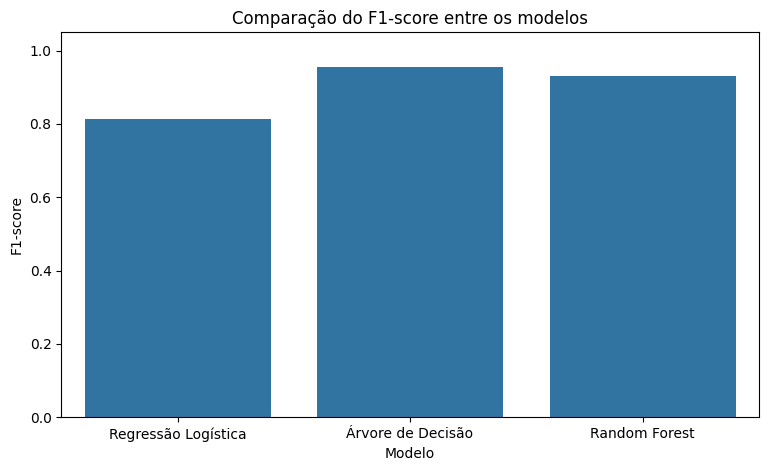

In [49]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_resultados,
    x='Modelo',
    y='F1-score'
)

plt.title('Comparação do F1-score entre os modelos')
plt.xlabel('Modelo')
plt.ylabel('F1-score')
plt.ylim(0, 1.05)
plt.show()

## 8. Treinamento do modelo escolhido

Com base nos resultados da validação cruzada, a Árvore de Decisão apresentou o melhor desempenho geral entre os modelos avaliados.

Por esse motivo, ela foi selecionada para a etapa de avaliação final, utilizando o conjunto de teste separado anteriormente.

In [50]:
modelo_final = Pipeline([
    ('preprocessamento', preprocessamento),
    ('modelo', DecisionTreeClassifier(random_state=42))
])

In [51]:
modelo_final.fit(X_train, y_train)

Pipeline(steps=[('preprocessamento',
                 Pipeline(steps=[('imputacao',
                                  SimpleImputer(strategy='median')),
                                 ('padronizacao', StandardScaler())])),
                ('modelo', DecisionTreeClassifier(random_state=42))])

In [52]:
y_pred = modelo_final.predict(X_test)

Avaliação no conjunto de teste

In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [54]:
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")

Acurácia: 0.9800
Precision: 0.9153
Recall: 0.9474
F1-score: 0.9310


In [55]:
print("Relatório de classificação:")
print(classification_report(y_test, y_pred))

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       343
           1       0.92      0.95      0.93        57

    accuracy                           0.98       400
   macro avg       0.95      0.97      0.96       400
weighted avg       0.98      0.98      0.98       400



Matriz de Confusão

In [56]:
from sklearn.metrics import confusion_matrix

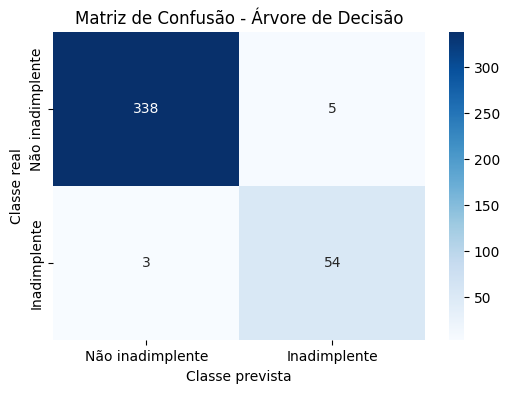

In [57]:
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    matriz,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Não inadimplente', 'Inadimplente'],
    yticklabels=['Não inadimplente', 'Inadimplente']
)

plt.title('Matriz de Confusão - Árvore de Decisão')
plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.show()

## 9. Conclusão

O objetivo deste projeto foi investigar se informações como idade, renda e valor do empréstimo poderiam ser utilizadas para identificar clientes com maior risco de inadimplência.

Durante a análise exploratória, foram observados padrões relevantes entre as características dos clientes e a ocorrência de inadimplência. A idade e o valor do empréstimo apresentaram relações mais evidentes com o comportamento dos clientes, enquanto a renda demonstrou menor associação com a variável-alvo.

Foram desenvolvidos e comparados três modelos de Machine Learning: Regressão Logística, Árvore de Decisão e Random Forest. Entre eles, a Árvore de Decisão apresentou o melhor desempenho geral durante a validação cruzada, sendo selecionada para a avaliação final.

No conjunto de teste, o modelo alcançou os seguintes resultados:

- **Acurácia:** 98,00%
- **Precision:** 91,53%
- **Recall:** 94,74%
- **F1-score:** 93,10%

O resultado mais relevante foi o Recall de 94,74%, indicando que o modelo conseguiu identificar corretamente 54 dos 57 clientes inadimplentes presentes no conjunto de teste.

### Resposta à pergunta de negócio

Sim, os resultados indicam que é possível identificar clientes com maior risco de inadimplência utilizando informações como idade e valor do empréstimo, por meio de modelos de Machine Learning.

A aplicação desse tipo de solução pode auxiliar instituições financeiras na análise de crédito, contribuindo para a identificação de perfis de maior risco e para decisões mais fundamentadas.

### Limitações e oportunidades de melhoria

Apesar dos resultados positivos, é importante considerar algumas limitações:

- A análise foi realizada com uma quantidade limitada de registros e poucas variáveis.
- Os resultados podem não representar o comportamento de clientes em cenários reais de concessão de crédito.
- Outras informações, como histórico de pagamentos, comprometimento de renda e histórico financeiro, poderiam contribuir para previsões mais completas.
- Seria interessante avaliar o modelo com novas bases de dados e diferentes cenários antes de considerar sua utilização em decisões reais.

Conclui-se que o projeto demonstrou o potencial da análise de dados e do Machine Learning como ferramentas de apoio à avaliação de risco de crédito.